# EDA 3 — ETTm1 (Electricity Transformer Temperature, 15 phút)
**Nguồn:** https://github.com/zhouhaoyi/ETDataset · **License:** CC BY-ND 4.0 (được dùng, KHÔNG phân phối bản đã sửa → không commit dữ liệu/bản xử lý) · **Paper gốc:** Zhou et al. (2021), *Informer*, AAAI 35(12):11106–11115, DOI 10.1609/aaai.v35i12.17325.

Nhiệt độ dầu máy biến áp `OT` (mục tiêu) và 6 biến tải: HUFL/HULL (tải cao hữu ích/vô ích), MUFL/MULL (trung), LUFL/LULL (thấp). Chia chuẩn trong benchmark: 12/4/4 tháng train/val/test.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from eda_utils import *
warnings.filterwarnings('ignore'); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 80
RAW = ROOT / 'data' / 'raw'
SUMMARY = {}  # các số chính, lưu ra reports/ để notebook so sánh dùng lại

## 1. Đọc dữ liệu, shape, kiểu

In [2]:
df = pd.read_csv(RAW/'ETTm1.csv', parse_dates=['date']).rename(columns={'date':'t'})
print('shape:', df.shape); display(df.head(3)); display(overview(df))
SUMMARY.update(dataset='ettm1', rows=len(df), cols=df.shape[1]-1, freq='15 phút', n_series=1)

shape: (69680, 8)


,t,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2,2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000


,dtype,n_missing,pct_missing,n_unique
t,datetime64[us],0,0.0,69680
HUFL,float64,0,0.0,667
HULL,float64,0,0.0,225
MUFL,float64,0,0.0,1110
MULL,float64,0,0.0,373
LUFL,float64,0,0.0,263
LULL,float64,0,0.0,134
OT,float64,0,0.0,700


## 2. Khoảng thời gian, bước thiếu, trùng lặp

In [3]:
g, missing = time_gaps(df['t'], '15min'); display(pd.Series(g))
print('NA:', df.isna().sum().sum(), '| dòng trùng:', df.duplicated().sum())
const_runs = (df.OT.diff()==0).astype(int); rl = const_runs.groupby((const_runs==0).cumsum()).sum().max()
print('Đoạn OT không đổi dài nhất (bước):', rl)
SUMMARY.update(start=g['start'], end=g['end'], missing_steps=g['n_missing_steps'], dup_ts=g['n_duplicated_ts'], n_na=int(df.isna().sum().sum()))
print(f"Nhận xét: {len(df)} dòng từ {g['start']} đến {g['end']}, {g['n_missing_steps']} bước thiếu, {g['n_duplicated_ts']} mốc trùng, {df.isna().sum().sum()} NA → lưới sạch. Đoạn OT đứng yên dài nhất {rl} bước liên tiếp.")

start              2016-07-01 00:00:00
end                2018-06-26 19:45:00
n_expected                       69680
n_unique                         69680
n_missing_steps                      0
n_duplicated_ts                      0
dtype: object

NA: 0 | dòng trùng: 0
Đoạn OT không đổi dài nhất (bước): 97
Nhận xét: 69680 dòng từ 2016-07-01 00:00:00 đến 2018-06-26 19:45:00, 0 bước thiếu, 0 mốc trùng, 0 NA → lưới sạch. Đoạn OT đứng yên dài nhất 97 bước liên tiếp.


## 3. Thống kê mô tả, phân phối, độ lệch

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
HUFL,69680.0,7.414,7.083,-23.242,5.827,8.841,11.788,24.180,-1.373,1.936
HULL,69680.0,2.261,2.041,-5.693,0.804,2.210,3.684,10.315,0.106,-0.308
MUFL,69680.0,4.322,6.829,-26.367,3.305,6.005,8.635,18.087,-1.604,2.353
MULL,69680.0,0.897,1.807,-6.041,-0.284,0.959,2.203,7.853,-0.131,-0.246
LUFL,69680.0,3.083,1.174,-1.188,2.315,2.833,3.655,8.498,1.243,2.780
LULL,69680.0,0.858,0.600,-1.371,0.670,0.975,1.218,3.046,-1.356,2.057
OT,69680.0,13.321,8.565,-4.221,6.964,11.396,18.079,46.007,0.967,0.771


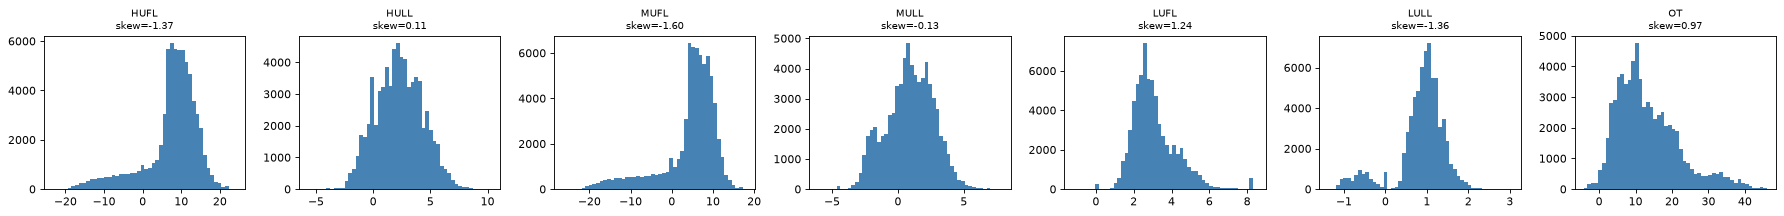

% giá trị âm theo cột: {'HUFL': 13.26, 'HULL': 13.37, 'MUFL': 16.83, 'MULL': 28.44, 'LUFL': 0.0, 'LULL': 9.57, 'OT': 0.89}


In [4]:
num = ['HUFL','HULL','MUFL','MULL','LUFL','LULL','OT']
st = shape_stats(df[num]); display(st); plot_dists(df, num)
SUMMARY.update(target_mean=st.loc['OT','mean'], target_skew=st.loc['OT','skew'], target_kurt=st.loc['OT','kurtosis'], target_cv=round(st.loc['OT','std']/st.loc['OT','mean'],3))
neg = (df[num]<0).mean().mul(100).round(2); print('% giá trị âm theo cột:', neg.to_dict())

In [5]:
print(f"Nhận xét: OT TB {st.loc['OT','mean']:.2f}, min {st.loc['OT','min']:.2f}, max {st.loc['OT','max']:.2f}; skew={st.loc['OT','skew']:.2f}, kurtosis={st.loc['OT','kurtosis']:.2f}. "
      f"Một số biến tải có giá trị âm (vd MULL {neg['MULL']}%, HULL {neg['HULL']}%) → dữ liệu đã được nhà cung cấp biến đổi, không nên lấy log; dùng chuẩn hoá z-score theo tập train như benchmark.")

Nhận xét: OT TB 13.32, min -4.22, max 46.01; skew=0.97, kurtosis=0.77. Một số biến tải có giá trị âm (vd MULL 28.44%, HULL 13.37%) → dữ liệu đã được nhà cung cấp biến đổi, không nên lấy log; dùng chuẩn hoá z-score theo tập train như benchmark.


## 4. Outlier (IQR 1.5)

In [6]:
out = iqr_outliers(df[num]); display(out); SUMMARY['target_outlier_pct'] = out.loc['OT','pct']
print(f"Nhận xét: OT có {int(out.loc['OT','n_outliers'])} điểm ({out.loc['OT','pct']}%) ngoài IQR; cột tải nhiều outlier nhất: {out.pct.idxmax()} ({out.pct.max()}%).")

,lower,upper,n_outliers,pct
HUFL,-3.1145,20.729500,7258.0,10.416
HULL,-3.5160,8.004000,235.0,0.337
MUFL,-4.6900,16.630000,8048.0,11.550
MULL,-4.0145,5.933500,328.0,0.471
LUFL,0.3050,5.665000,2153.0,3.090
LULL,-0.1520,2.040000,6839.0,9.815
OT,-9.7085,34.751501,1894.0,2.718


Nhận xét: OT có 1894 điểm (2.718%) ngoài IQR; cột tải nhiều outlier nhất: MUFL (11.55%).


## 5. Xu hướng & mùa vụ

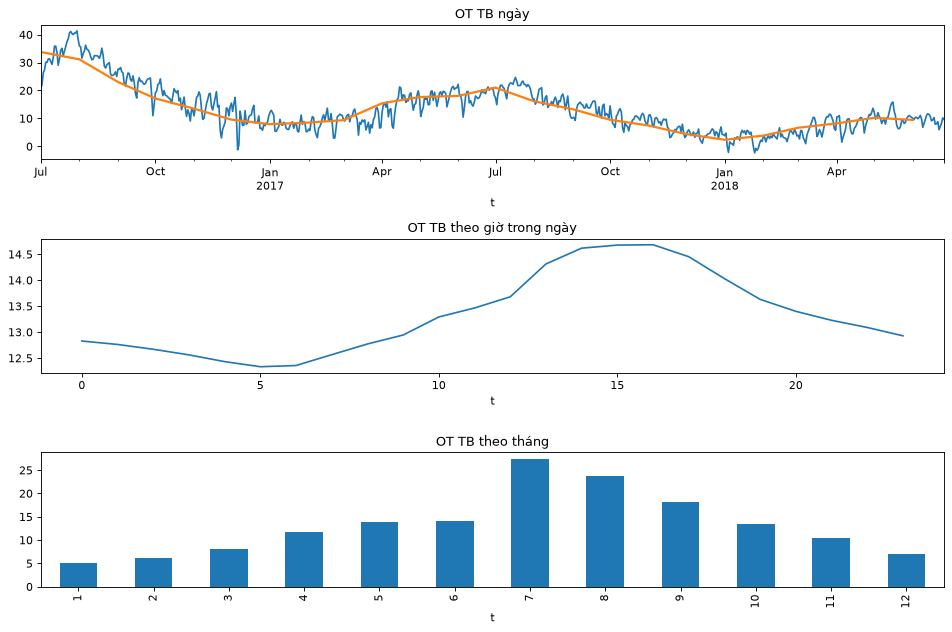

,count,mean,std,min,25%,50%,75%,max
train,34560.0,17.12,9.17,-4.22,9.99,15.76,21.88,46.01
val,11520.0,15.57,4.97,2.53,11.68,15.62,19.70,27.93
test,11520.0,4.84,3.15,-3.73,2.88,4.50,6.68,14.77


In [7]:
s = df.set_index('t')['OT']
fig, ax = plt.subplots(3,1, figsize=(12,8))
s.resample('D').mean().plot(ax=ax[0], title='OT TB ngày'); s.resample('MS').mean().plot(ax=ax[0], lw=2)
s.groupby(s.index.hour).mean().plot(ax=ax[1], title='OT TB theo giờ trong ngày'); s.groupby(s.index.month).mean().plot.bar(ax=ax[2], title='OT TB theo tháng')
plt.tight_layout(); plt.show()
n_tr = 12*30*96; n_va = 4*30*96
parts = {'train': s.iloc[:n_tr], 'val': s.iloc[n_tr:n_tr+n_va], 'test': s.iloc[n_tr+n_va:n_tr+2*n_va]}
dsplit = pd.DataFrame({k: v.describe() for k,v in parts.items()}).T.round(2); display(dsplit)
SUMMARY['split_means'] = dsplit['mean'].to_dict()

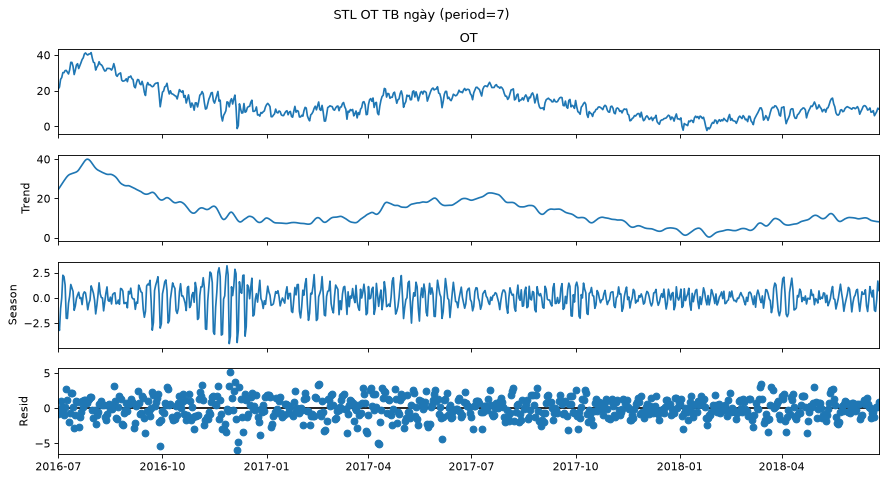

STL ngày: {'trend_strength': np.float64(0.968), 'seasonal_strength': np.float64(0.421)} | STL 15p (period=96): {'trend_strength': np.float64(0.988), 'seasonal_strength': np.float64(0.596)}


In [8]:
sd = s.resample('D').mean(); sw = stl_strength(sd, period=7, title='STL OT TB ngày (period=7)')
sday = stl_strength(s, period=96, plot=False); print('STL ngày:', sw, '| STL 15p (period=96):', sday)
SUMMARY.update(trend_strength=sw['trend_strength'], seasonal_strength=sday['seasonal_strength'])

In [9]:
print(f"Nhận xét: TB OT theo split chuẩn train/val/test = {dsplit['mean'].to_dict()} → có trôi phân phối giữa các đoạn (cần chuẩn hoá theo train và cẩn thận khi so sánh). "
      f"Độ mạnh xu hướng (chuỗi ngày) = {sw['trend_strength']}, mùa ngày (period 96) = {sday['seasonal_strength']} → OT chủ yếu là biến động chậm, mùa ngày yếu.")

Nhận xét: TB OT theo split chuẩn train/val/test = {'train': 17.12, 'val': 15.57, 'test': 4.84} → có trôi phân phối giữa các đoạn (cần chuẩn hoá theo train và cẩn thận khi so sánh). Độ mạnh xu hướng (chuỗi ngày) = 0.968, mùa ngày (period 96) = 0.596 → OT chủ yếu là biến động chậm, mùa ngày yếu.


## 6. ACF/PACF

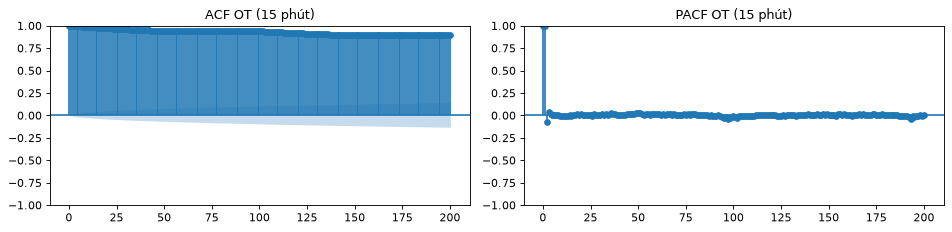

{'lag1': np.float64(0.999), 'lag4': np.float64(0.994), 'lag96': np.float64(0.94), 'lag672': np.float64(0.87)}
Nhận xét: lag1=0.999 (đúng như review: gần 1) → mô hình naive 'giá trị trước' đã rất mạnh ở chân trời ngắn; phải luôn có baseline naive/seasonal naive. lag96 (1 ngày)=0.94, lag672 (1 tuần)=0.87.


In [10]:
acf_pacf(s, lags=200, title='OT (15 phút)')
ac = autocorrs(s, [1,4,96,96*7]); print(ac); SUMMARY['acf'] = ac
print(f"Nhận xét: lag1={ac['lag1']} (đúng như review: gần 1) → mô hình naive 'giá trị trước' đã rất mạnh ở chân trời ngắn; phải luôn có baseline naive/seasonal naive. lag96 (1 ngày)={ac['lag96']}, lag672 (1 tuần)={ac['lag672']}.")

## 7. Kiểm định dừng

In [11]:
res = pd.DataFrame([stationarity(s, 'OT 15p'), stationarity(sd, 'OT TB ngày'), stationarity(sd.diff(), 'OT ngày, sai phân 1')]); display(res)
SUMMARY['stationarity'] = res.set_index('series')['kết luận'].to_dict()
print('Nhận xét:', '; '.join(f"{r.series}: ADF p={r.ADF_p}, KPSS p={r['KPSS_p(bị chặn 0.01-0.1)']} → {r['kết luận']}" for _, r in res.iterrows()))

,series,n,ADF_stat,ADF_p,KPSS_stat,KPSS_p(bị chặn 0.01-0.1),kết luận
0,OT 15p,69680,-4.192,0.0007,19.056,0.01,"trái chiều: ADF nói dừng, KPSS nói không dừng ..."
1,OT TB ngày,726,-2.247,0.1895,1.843,0.01,không dừng
2,"OT ngày, sai phân 1",725,-12.661,0.0000,0.065,0.10,dừng


Nhận xét: OT 15p: ADF p=0.0007, KPSS p=0.01 → trái chiều: ADF nói dừng, KPSS nói không dừng (thường do xu hướng/mùa vụ → kiểm lại sau sai phân); OT TB ngày: ADF p=0.1895, KPSS p=0.01 → không dừng; OT ngày, sai phân 1: ADF p=0.0, KPSS p=0.1 → dừng


## 8. Tương quan với biến ngoại sinh (biến tải)

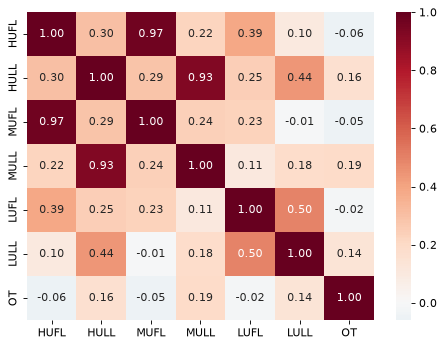

MULL    0.194
HULL    0.158
LULL    0.137
HUFL   -0.060
MUFL   -0.049
LUFL   -0.021
Name: OT, dtype: float64

HUFL–MUFL: 0.987 | HULL–MULL: 0.931
Nhận xét: tương quan với OT: MULL=0.19, HULL=0.16, LULL=0.14, HUFL=-0.06, MUFL=-0.05, LUFL=-0.02. Các biến tải tương quan chéo cao (HUFL–MUFL r=0.99) → đa cộng tuyến; benchmark thường chạy cả hai chế độ univariate (S) và multivariate (M).


In [12]:
corr = df[num].corr(method='spearman'); plt.figure(figsize=(7,5)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0); plt.show()
c = corr['OT'].drop('OT').sort_values(key=abs, ascending=False); display(c.round(3))
print('HUFL–MUFL:', round(df.HUFL.corr(df.MUFL),3), '| HULL–MULL:', round(df.HULL.corr(df.MULL),3))
SUMMARY['top_exog'] = c.round(3).head(3).to_dict()
print(f"Nhận xét: tương quan với OT: {', '.join(f'{k}={v:.2f}' for k,v in c.items())}. Các biến tải tương quan chéo cao (HUFL–MUFL r={df.HUFL.corr(df.MUFL):.2f}) → đa cộng tuyến; benchmark thường chạy cả hai chế độ univariate (S) và multivariate (M).")

In [13]:
import json; (ROOT/'reports').mkdir(exist_ok=True)
json.dump(SUMMARY, open(ROOT/'reports'/f"summary_{SUMMARY['dataset']}.json", 'w'), ensure_ascii=False, indent=1, default=str)
SUMMARY

{'dataset': 'ettm1',
 'rows': 69680,
 'cols': 7,
 'freq': '15 phút',
 'n_series': 1,
 'start': Timestamp('2016-07-01 00:00:00'),
 'end': Timestamp('2018-06-26 19:45:00'),
 'missing_steps': 0,
 'dup_ts': 0,
 'n_na': 0,
 'target_mean': np.float64(13.321),
 'target_skew': np.float64(0.967),
 'target_kurt': np.float64(0.771),
 'target_cv': np.float64(0.643),
 'target_outlier_pct': np.float64(2.718),
 'split_means': {'train': 17.12, 'val': 15.57, 'test': 4.84},
 'trend_strength': np.float64(0.968),
 'seasonal_strength': np.float64(0.596),
 'acf': {'lag1': np.float64(0.999),
  'lag4': np.float64(0.994),
  'lag96': np.float64(0.94),
  'lag672': np.float64(0.87)},
 'stationarity': {'OT 15p': 'trái chiều: ADF nói dừng, KPSS nói không dừng (thường do xu hướng/mùa vụ → kiểm lại sau sai phân)',
  'OT TB ngày': 'không dừng',
  'OT ngày, sai phân 1': 'dừng'},
 'top_exog': {'MULL': 0.194, 'HULL': 0.158, 'LULL': 0.137}}